In [6]:

import pandas as pd
import os

file_path = "/content/teams.csv"

print("Checking file location...")

if os.path.exists(file_path):
    df = pd.read_csv(file_path)

    print("Success! Your dataset is loaded.")
    print("Rows and columns:", df.shape)

    df.columns = (
        df.columns.astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"\s+", "_", regex=True)
    )

    df = df.dropna(how="all")
    df = df.dropna(axis=1, how="all")
    df = df.drop_duplicates()

    print("\nDataset after basic cleaning:", df.shape)
    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nFirst five rows:")
    display(df.head())

    print("\nMissing values:")
    display(df.isnull().sum().to_frame("missing_values"))

else:
    print("File not found at /content/teams.csv")
    print("Files currently in /content:")
    print(os.listdir("/content"))
import pandas as pd
import os

# Find the uploaded CSV file
file_path = "/content/teams.csv"

if not os.path.exists(file_path):
    # Search for the file in the Colab file system
    for root, dirs, files in os.walk("/"):
        if "teams.csv" in files:
            file_path = os.path.join(root, "teams.csv")
            break

# Load and clean the dataset
if os.path.exists(file_path):
    df = pd.read_csv(file_path)

    print("SUCCESS: File loaded!")
    print("File location:", file_path)
    print("Original size:", df.shape)

    # Clean column names
    df.columns = (
        df.columns.astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"\s+", "_", regex=True)
    )

    # Remove completely empty rows and columns
    df = df.dropna(how="all")
    df = df.dropna(axis=1, how="all")

    # Remove duplicate rows
    df = df.drop_duplicates()

    print("\nCleaned dataset size:", df.shape)
    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nFirst five rows:")
    display(df.head())

    print("\nMissing values per column:")
    display(df.isnull().sum().to_frame("missing_values"))

else:
    print("Could not locate teams.csv.")
    print("Please use the upload button in the Files panel.")



Checking file location...
File not found at /content/teams.csv
Files currently in /content:
['.config', 'sample_data']
SUCCESS: File loaded!
File location: /teams.csv
Original size: (160, 107)

Cleaned dataset size: (160, 107)

Column names:
['team', 'season', 'name', 'team.1', 'position', 'situation', 'games_played', 'xgoalspercentage', 'corsipercentage', 'fenwickpercentage', 'icetime', 'xongoalfor', 'xgoalsfor', 'xreboundsfor', 'xfreezefor', 'xplaystoppedfor', 'xplaycontinuedinzonefor', 'xplaycontinuedoutsidezonefor', 'flurryadjustedxgoalsfor', 'scorevenueadjustedxgoalsfor', 'flurryscorevenueadjustedxgoalsfor', 'shotsongoalfor', 'missedshotsfor', 'blockedshotattemptsfor', 'shotattemptsfor', 'goalsfor', 'reboundsfor', 'reboundgoalsfor', 'freezefor', 'playstoppedfor', 'playcontinuedinzonefor', 'playcontinuedoutsidezonefor', 'savedshotsongoalfor', 'savedunblockedshotattemptsfor', 'penaltiesfor', 'penalityminutesfor', 'faceoffswonfor', 'hitsfor', 'takeawaysfor', 'giveawaysfor', 'lowdange

,team,season,name,team.1,position,situation,games_played,xgoalspercentage,corsipercentage,fenwickpercentage,...,scoreadjustedshotsattemptsagainst,unblockedshotattemptsagainst,scoreadjustedunblockedshotattemptsagainst,dzonegiveawaysagainst,xgoalsfromxreboundsofshotsagainst,xgoalsfromactualreboundsofshotsagainst,reboundxgoalsagainst,totalshotcreditagainst,scoreadjustedtotalshotcreditagainst,scoreflurryadjustedtotalshotcreditagainst
0,NYR,2025,NYR,NYR,Team Level,other,82,0.37,0.50,0.48,...,287.00,224.0,224.00,11.0,3.44,7.77,7.12,44.88,44.88,42.60
1,NYR,2025,NYR,NYR,Team Level,all,82,0.47,0.49,0.48,...,4936.35,3609.0,3637.64,620.0,41.18,66.94,67.31,242.32,243.60,236.42
2,NYR,2025,NYR,NYR,Team Level,5on5,82,0.48,0.49,0.48,...,3890.35,2781.0,2809.64,563.0,27.38,41.85,42.17,148.93,150.21,147.77
3,NYR,2025,NYR,NYR,Team Level,4on5,82,0.09,0.10,0.12,...,673.00,526.0,526.00,4.0,9.60,16.09,16.79,41.69,41.69,39.30
4,NYR,2025,NYR,NYR,Team Level,5on4,82,0.87,0.87,0.86,...,86.00,78.0,78.00,42.0,0.77,1.23,1.23,6.82,6.82,6.75



Missing values per column:


,missing_values
team,0
season,0
name,0
team.1,0
position,0
...,...
xgoalsfromactualreboundsofshotsagainst,0
reboundxgoalsagainst,0
totalshotcreditagainst,0
scoreadjustedtotalshotcreditagainst,0


In [7]:

# 1. Check the size of the dataset
print("Number of rows and columns:", df.shape)

# 2. See all column names
print("\nALL COLUMN NAMES:")
print(df.columns.tolist())

# 3. Count teams
print("\nNUMBER OF UNIQUE TEAMS:")
print(df["team"].nunique())

# 4. List the teams
print("\nTEAMS IN THE DATA:")
print(sorted(df["team"].dropna().unique()))

# 5. Check seasons
if "season" in df.columns:
    print("\nSEASONS:")
    print(df["season"].value_counts(dropna=False))

# 6. Check situations, if available
if "situation" in df.columns:
    print("\nSITUATIONS:")
    print(df["situation"].value_counts(dropna=False))

# 7. Count missing values
print("\nMISSING VALUES BY COLUMN:")
display(df.isnull().sum().to_frame("missing_values"))

# 8. Preview the first ten rows
print("\nFIRST TEN ROWS:")
display(df.head(10))


Number of rows and columns: (160, 107)

ALL COLUMN NAMES:
['team', 'season', 'name', 'team.1', 'position', 'situation', 'games_played', 'xgoalspercentage', 'corsipercentage', 'fenwickpercentage', 'icetime', 'xongoalfor', 'xgoalsfor', 'xreboundsfor', 'xfreezefor', 'xplaystoppedfor', 'xplaycontinuedinzonefor', 'xplaycontinuedoutsidezonefor', 'flurryadjustedxgoalsfor', 'scorevenueadjustedxgoalsfor', 'flurryscorevenueadjustedxgoalsfor', 'shotsongoalfor', 'missedshotsfor', 'blockedshotattemptsfor', 'shotattemptsfor', 'goalsfor', 'reboundsfor', 'reboundgoalsfor', 'freezefor', 'playstoppedfor', 'playcontinuedinzonefor', 'playcontinuedoutsidezonefor', 'savedshotsongoalfor', 'savedunblockedshotattemptsfor', 'penaltiesfor', 'penalityminutesfor', 'faceoffswonfor', 'hitsfor', 'takeawaysfor', 'giveawaysfor', 'lowdangershotsfor', 'mediumdangershotsfor', 'highdangershotsfor', 'lowdangerxgoalsfor', 'mediumdangerxgoalsfor', 'highdangerxgoalsfor', 'lowdangergoalsfor', 'mediumdangergoalsfor', 'highdanger

,missing_values
team,0
season,0
name,0
team.1,0
position,0
...,...
xgoalsfromactualreboundsofshotsagainst,0
reboundxgoalsagainst,0
totalshotcreditagainst,0
scoreadjustedtotalshotcreditagainst,0



FIRST TEN ROWS:


,team,season,name,team.1,position,situation,games_played,xgoalspercentage,corsipercentage,fenwickpercentage,...,scoreadjustedshotsattemptsagainst,unblockedshotattemptsagainst,scoreadjustedunblockedshotattemptsagainst,dzonegiveawaysagainst,xgoalsfromxreboundsofshotsagainst,xgoalsfromactualreboundsofshotsagainst,reboundxgoalsagainst,totalshotcreditagainst,scoreadjustedtotalshotcreditagainst,scoreflurryadjustedtotalshotcreditagainst
0,NYR,2025,NYR,NYR,Team Level,other,82,0.37,0.50,0.48,...,287.00,224.0,224.00,11.0,3.44,7.77,7.12,44.88,44.88,42.60
1,NYR,2025,NYR,NYR,Team Level,all,82,0.47,0.49,0.48,...,4936.35,3609.0,3637.64,620.0,41.18,66.94,67.31,242.32,243.60,236.42
2,NYR,2025,NYR,NYR,Team Level,5on5,82,0.48,0.49,0.48,...,3890.35,2781.0,2809.64,563.0,27.38,41.85,42.17,148.93,150.21,147.77
3,NYR,2025,NYR,NYR,Team Level,4on5,82,0.09,0.10,0.12,...,673.00,526.0,526.00,4.0,9.60,16.09,16.79,41.69,41.69,39.30
4,NYR,2025,NYR,NYR,Team Level,5on4,82,0.87,0.87,0.86,...,86.00,78.0,78.00,42.0,0.77,1.23,1.23,6.82,6.82,6.75
5,LAK,2025,LAK,LAK,Team Level,other,82,0.54,0.47,0.43,...,342.00,265.0,265.00,5.0,4.36,2.41,2.41,35.95,35.95,33.05
6,LAK,2025,LAK,LAK,Team Level,all,82,0.51,0.52,0.52,...,4736.48,3406.0,3420.33,518.0,39.29,49.92,49.92,228.24,229.39,221.73
7,LAK,2025,LAK,LAK,Team Level,5on5,82,0.52,0.52,0.52,...,3787.48,2645.0,2659.33,467.0,26.56,36.28,36.32,142.12,143.27,141.01
8,LAK,2025,LAK,LAK,Team Level,4on5,82,0.11,0.15,0.17,...,508.00,407.0,407.00,4.0,7.63,10.55,10.51,43.76,43.76,41.30
9,LAK,2025,LAK,LAK,Team Level,5on4,82,0.85,0.86,0.84,...,99.00,89.0,89.00,42.0,0.74,0.69,0.69,6.42,6.42,6.37


In [8]:

# Show the available statistics and their data types

print("COLUMN NAMES AND DATA TYPES")

df.info()

print("\nEXAMPLE STATISTICS FROM THE DATA")

display(df.head(15))


COLUMN NAMES AND DATA TYPES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 160 entries, 0 to 159
Columns: 107 entries, team to scoreflurryadjustedtotalshotcreditagainst
dtypes: float64(100), int64(2), object(5)
memory usage: 133.9+ KB

EXAMPLE STATISTICS FROM THE DATA


,team,season,name,team.1,position,situation,games_played,xgoalspercentage,corsipercentage,fenwickpercentage,...,scoreadjustedshotsattemptsagainst,unblockedshotattemptsagainst,scoreadjustedunblockedshotattemptsagainst,dzonegiveawaysagainst,xgoalsfromxreboundsofshotsagainst,xgoalsfromactualreboundsofshotsagainst,reboundxgoalsagainst,totalshotcreditagainst,scoreadjustedtotalshotcreditagainst,scoreflurryadjustedtotalshotcreditagainst
0,NYR,2025,NYR,NYR,Team Level,other,82,0.37,0.50,0.48,...,287.00,224.0,224.00,11.0,3.44,7.77,7.12,44.88,44.88,42.60
1,NYR,2025,NYR,NYR,Team Level,all,82,0.47,0.49,0.48,...,4936.35,3609.0,3637.64,620.0,41.18,66.94,67.31,242.32,243.60,236.42
2,NYR,2025,NYR,NYR,Team Level,5on5,82,0.48,0.49,0.48,...,3890.35,2781.0,2809.64,563.0,27.38,41.85,42.17,148.93,150.21,147.77
3,NYR,2025,NYR,NYR,Team Level,4on5,82,0.09,0.10,0.12,...,673.00,526.0,526.00,4.0,9.60,16.09,16.79,41.69,41.69,39.30
4,NYR,2025,NYR,NYR,Team Level,5on4,82,0.87,0.87,0.86,...,86.00,78.0,78.00,42.0,0.77,1.23,1.23,6.82,6.82,6.75
5,LAK,2025,LAK,LAK,Team Level,other,82,0.54,0.47,0.43,...,342.00,265.0,265.00,5.0,4.36,2.41,2.41,35.95,35.95,33.05
6,LAK,2025,LAK,LAK,Team Level,all,82,0.51,0.52,0.52,...,4736.48,3406.0,3420.33,518.0,39.29,49.92,49.92,228.24,229.39,221.73
7,LAK,2025,LAK,LAK,Team Level,5on5,82,0.52,0.52,0.52,...,3787.48,2645.0,2659.33,467.0,26.56,36.28,36.32,142.12,143.27,141.01
8,LAK,2025,LAK,LAK,Team Level,4on5,82,0.11,0.15,0.17,...,508.00,407.0,407.00,4.0,7.63,10.55,10.51,43.76,43.76,41.30
9,LAK,2025,LAK,LAK,Team Level,5on4,82,0.85,0.86,0.84,...,99.00,89.0,89.00,42.0,0.74,0.69,0.69,6.42,6.42,6.37


Dataset loaded.
Rows: 160
Columns: 107

Column names:
['team', 'season', 'name', 'team.1', 'position', 'situation', 'games_played', 'xgoalspercentage', 'corsipercentage', 'fenwickpercentage', 'icetime', 'xongoalfor', 'xgoalsfor', 'xreboundsfor', 'xfreezefor', 'xplaystoppedfor', 'xplaycontinuedinzonefor', 'xplaycontinuedoutsidezonefor', 'flurryadjustedxgoalsfor', 'scorevenueadjustedxgoalsfor', 'flurryscorevenueadjustedxgoalsfor', 'shotsongoalfor', 'missedshotsfor', 'blockedshotattemptsfor', 'shotattemptsfor', 'goalsfor', 'reboundsfor', 'reboundgoalsfor', 'freezefor', 'playstoppedfor', 'playcontinuedinzonefor', 'playcontinuedoutsidezonefor', 'savedshotsongoalfor', 'savedunblockedshotattemptsfor', 'penaltiesfor', 'penalityminutesfor', 'faceoffswonfor', 'hitsfor', 'takeawaysfor', 'giveawaysfor', 'lowdangershotsfor', 'mediumdangershotsfor', 'highdangershotsfor', 'lowdangerxgoalsfor', 'mediumdangerxgoalsfor', 'highdangerxgoalsfor', 'lowdangergoalsfor', 'mediumdangergoalsfor', 'highdangergoal

,team,season,name,team.1,position,situation,games_played,xgoalspercentage,corsipercentage,fenwickpercentage,...,scoreadjustedshotsattemptsagainst,unblockedshotattemptsagainst,scoreadjustedunblockedshotattemptsagainst,dzonegiveawaysagainst,xgoalsfromxreboundsofshotsagainst,xgoalsfromactualreboundsofshotsagainst,reboundxgoalsagainst,totalshotcreditagainst,scoreadjustedtotalshotcreditagainst,scoreflurryadjustedtotalshotcreditagainst
1,NYR,2025,NYR,NYR,Team Level,all,82,0.47,0.49,0.48,...,4936.35,3609.0,3637.64,620.0,41.18,66.94,67.31,242.32,243.60,236.42
6,LAK,2025,LAK,LAK,Team Level,all,82,0.51,0.52,0.52,...,4736.48,3406.0,3420.33,518.0,39.29,49.92,49.92,228.24,229.39,221.73
11,NYI,2025,NYI,NYI,Team Level,all,82,0.48,0.50,0.50,...,4883.76,3548.0,3568.52,557.0,41.95,67.16,67.16,250.90,252.01,244.35
16,MTL,2025,MTL,MTL,Team Level,all,82,0.50,0.48,0.49,...,4910.92,3486.0,3482.81,569.0,39.94,64.46,64.51,248.82,249.13,239.56
21,NJD,2025,NJD,NJD,Team Level,all,82,0.51,0.52,0.52,...,4711.85,3412.0,3445.28,599.0,39.65,59.57,59.57,229.54,231.19,224.57



Statistics found:
Goals for: goalsfor
Goals against: goalsagainst
Expected goals for: xgoalsfor
Expected goals against: xgoalsagainst
Shots on goal for: shotsongoalfor
Shots on goal against: shotsongoalagainst

TEAM PERFORMANCE SUMMARY:


,team,goalsfor,goalsagainst,goal_differential,xgoalsfor,xgoalsagainst,expected_goal_differential,shotsongoalfor,shotsongoalagainst,shot_differential,goals_minus_expected
1,NYR,235.0,249.0,-14.0,237.20,268.44,-31.24,2066.0,2364.0,-298.0,-2.20
6,LAK,220.0,238.0,-18.0,248.96,238.87,10.09,2298.0,2230.0,68.0,-28.96
11,NYI,229.0,236.0,-7.0,256.50,276.12,-19.62,2312.0,2271.0,41.0,-27.50
16,MTL,279.0,251.0,28.0,268.31,273.39,-5.08,2157.0,2282.0,-125.0,10.69
21,NJD,226.0,253.0,-27.0,261.20,249.47,11.73,2426.0,2247.0,179.0,-35.20
26,TOR,252.0,295.0,-43.0,238.41,285.49,-47.08,2160.0,2663.0,-503.0,13.59
31,OTT,275.0,245.0,30.0,271.89,221.02,50.87,2372.0,2001.0,371.0,3.11
36,BOS,268.0,247.0,21.0,247.57,277.57,-30.00,2216.0,2436.0,-220.0,20.43
41,EDM,282.0,265.0,17.0,274.56,257.25,17.31,2441.0,2190.0,251.0,7.44
46,TBL,286.0,229.0,57.0,284.40,241.48,42.92,2307.0,2191.0,116.0,1.60


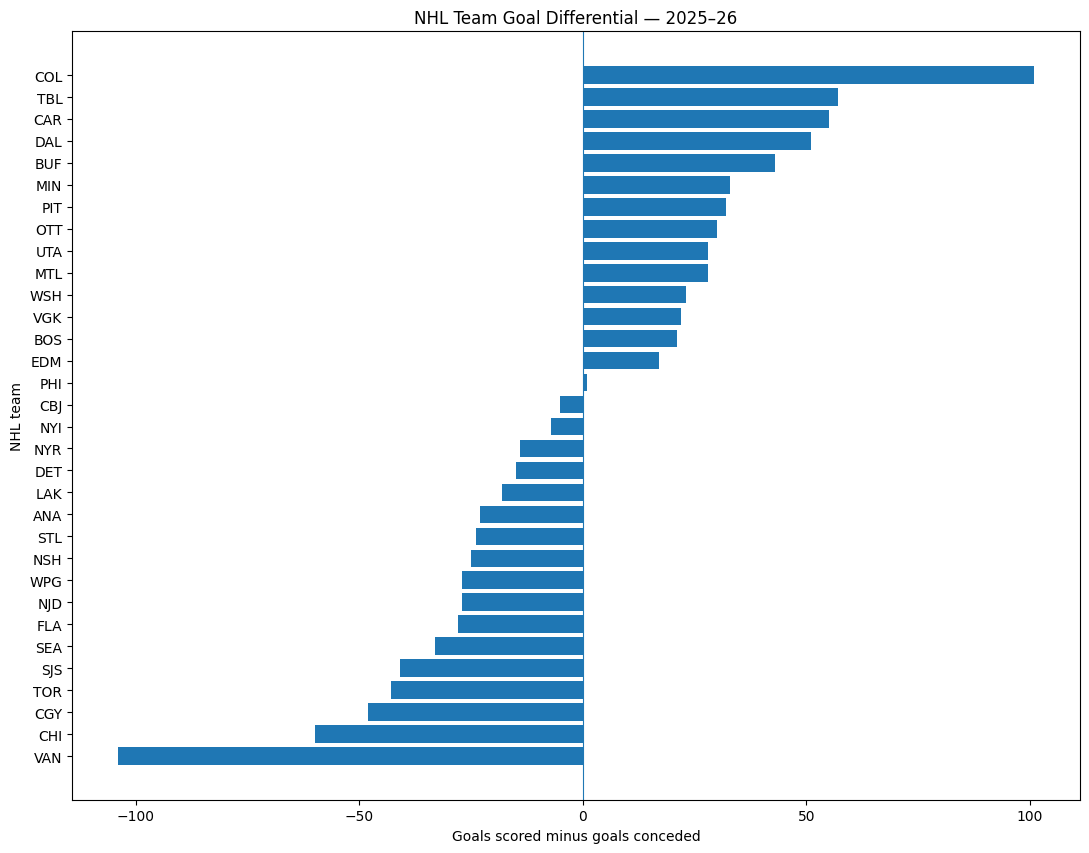

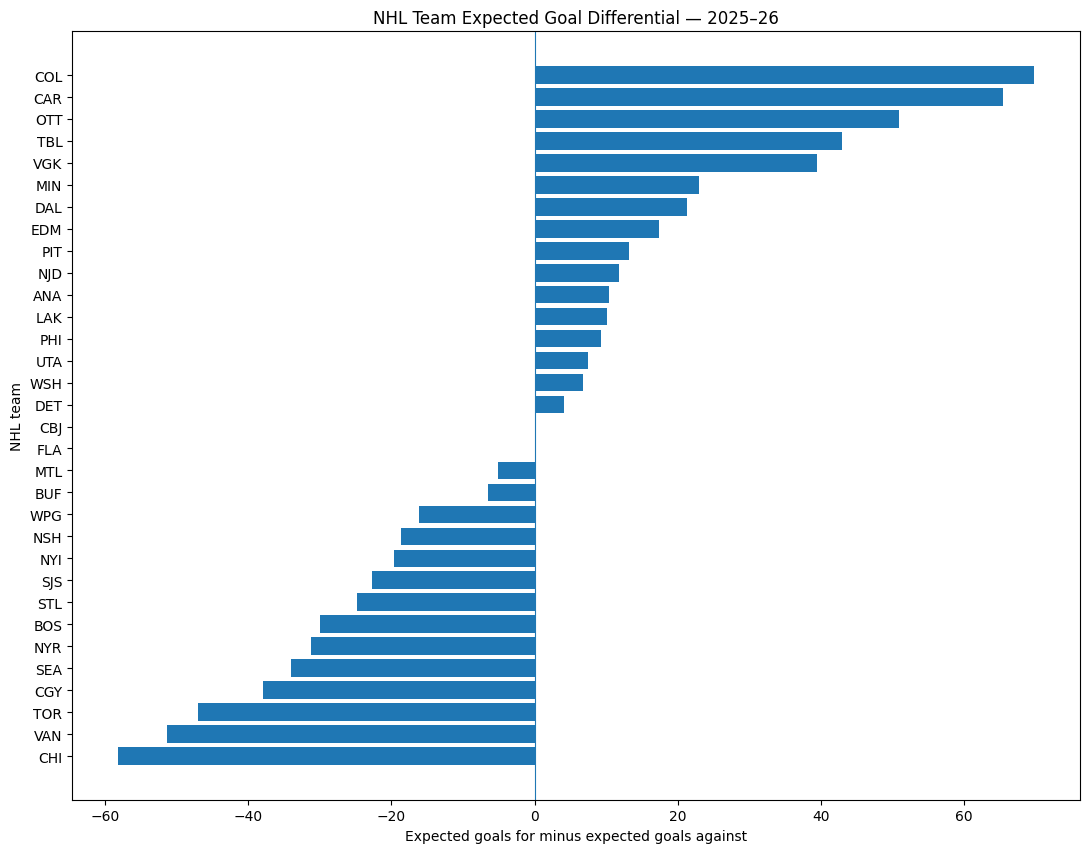

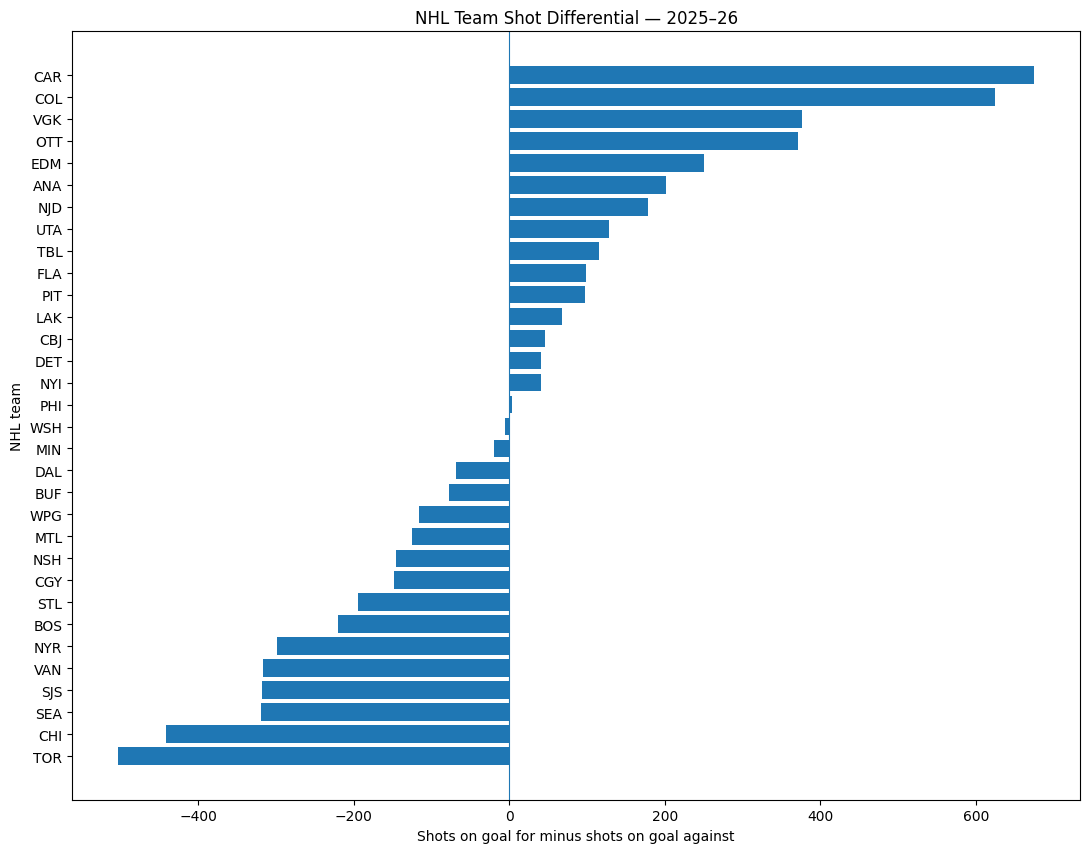


Analysis complete.
Summary saved as nhl_team_performance_summary.csv


In [9]:

import pandas as pd
import matplotlib.pyplot as plt
import os
import glob

# ------------------------------------------
# 1. LOAD THE FILE IF df IS NOT AVAILABLE
# ------------------------------------------
if "df" not in globals():
    files = glob.glob("/content/teams.csv")
    if not files:
        raise FileNotFoundError(
            "teams.csv was not found. Upload it using the Files panel."
        )
    df = pd.read_csv(files[0])

# ------------------------------------------
# 2. CLEAN COLUMN NAMES
# ------------------------------------------
df.columns = df.columns.astype(str).str.strip().str.lower()

# Give repeated column names unique names
new_columns = []
seen = {}
for col in df.columns:
    seen[col] = seen.get(col, 0) + 1
    if seen[col] == 1:
        new_columns.append(col)
    else:
        new_columns.append(f"{col}_{seen[col]}")

df.columns = new_columns

# Remove completely empty rows and columns
df = df.dropna(how="all").dropna(axis=1, how="all")

print("Dataset loaded.")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("\nColumn names:")
print(df.columns.tolist())

# ------------------------------------------
# 3. SELECT OVERALL TEAM DATA
# ------------------------------------------
if "situation" not in df.columns:
    raise ValueError("The situation column was not found.")

print("\nAvailable situations:")
print(df["situation"].value_counts(dropna=False))

overall = df[
    df["situation"].astype(str).str.strip().str.lower() == "all"
].copy()

if overall.empty:
    raise ValueError(
        "No rows labelled 'all' were found. Check the situations above."
    )

# Use the first team column
team_col = "team"
if team_col not in overall.columns:
    raise ValueError("The team column was not found.")

overall = overall.dropna(subset=[team_col])
overall = overall.drop_duplicates(subset=[team_col])

print("\nNumber of teams in overall data:", len(overall))
display(overall.head())

# ------------------------------------------
# 4. FIND STATISTICAL COLUMNS
# ------------------------------------------
def find_column(possible_names):
    for name in possible_names:
        if name in overall.columns:
            return name
    return None

goals_for_col = find_column(["goalsfor", "goals_for"])
goals_against_col = find_column(["goalsagainst", "goals_against"])
xgf_col = find_column(["xgoalsfor", "x_goals_for"])
xga_col = find_column(["xgoalsagainst", "x_goals_against"])
shots_for_col = find_column([
    "shotsongoalfor", "shots_on_goal_for"
])
shots_against_col = find_column([
    "shotsongoalagainst", "shots_on_goal_against"
])

print("\nStatistics found:")
for label, column in [
    ("Goals for", goals_for_col),
    ("Goals against", goals_against_col),
    ("Expected goals for", xgf_col),
    ("Expected goals against", xga_col),
    ("Shots on goal for", shots_for_col),
    ("Shots on goal against", shots_against_col)
]:
    print(label + ":", column if column else "Not found")

# ------------------------------------------
# 5. CALCULATE TEAM METRICS
# ------------------------------------------
metrics = overall.copy()

metric_columns = [
    goals_for_col, goals_against_col,
    xgf_col, xga_col, shots_for_col, shots_against_col
]

for col in metric_columns:
    if col is not None:
        metrics[col] = pd.to_numeric(metrics[col], errors="coerce")

if goals_for_col and goals_against_col:
    metrics["goal_differential"] = (
        metrics[goals_for_col] - metrics[goals_against_col]
    )

if xgf_col and xga_col:
    metrics["expected_goal_differential"] = (
        metrics[xgf_col] - metrics[xga_col]
    )

if shots_for_col and shots_against_col:
    metrics["shot_differential"] = (
        metrics[shots_for_col] - metrics[shots_against_col]
    )

if goals_for_col and xgf_col:
    metrics["goals_minus_expected"] = (
        metrics[goals_for_col] - metrics[xgf_col]
    )

# ------------------------------------------
# 6. DISPLAY THE RESULTS
# ------------------------------------------
columns_to_show = [team_col]

for col in [
    goals_for_col, goals_against_col, "goal_differential",
    xgf_col, xga_col, "expected_goal_differential",
    shots_for_col, shots_against_col, "shot_differential",
    "goals_minus_expected"
]:
    if col and col in metrics.columns and col not in columns_to_show:
        columns_to_show.append(col)

results = metrics[columns_to_show].copy()

print("\nTEAM PERFORMANCE SUMMARY:")
display(results.round(2))

# ------------------------------------------
# 7. CREATE COMPARISON CHARTS
# ------------------------------------------
def plot_metric(column, title, xlabel):
    if column not in metrics.columns:
        print("Chart skipped because this metric is unavailable:", column)
        return

    chart_data = metrics[[team_col, column]].dropna()
    chart_data = chart_data.sort_values(column, ascending=True)

    plt.figure(figsize=(11, max(7, len(chart_data) * 0.27)))
    plt.barh(chart_data[team_col], chart_data[column])
    plt.axvline(0, linewidth=0.8)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("NHL team")
    plt.grid(False)
    plt.tight_layout()
    plt.show()

plot_metric(
    "goal_differential",
    "NHL Team Goal Differential — 2025–26",
    "Goals scored minus goals conceded"
)

plot_metric(
    "expected_goal_differential",
    "NHL Team Expected Goal Differential — 2025–26",
    "Expected goals for minus expected goals against"
)

plot_metric(
    "shot_differential",
    "NHL Team Shot Differential — 2025–26",
    "Shots on goal for minus shots on goal against"
)

# ------------------------------------------
# 8. SAVE THE SUMMARY AS A CSV FILE
# ------------------------------------------
results.to_csv(
    "/content/nhl_team_performance_summary.csv",
    index=False
)

print("\nAnalysis complete.")
print("Summary saved as nhl_team_performance_summary.csv")


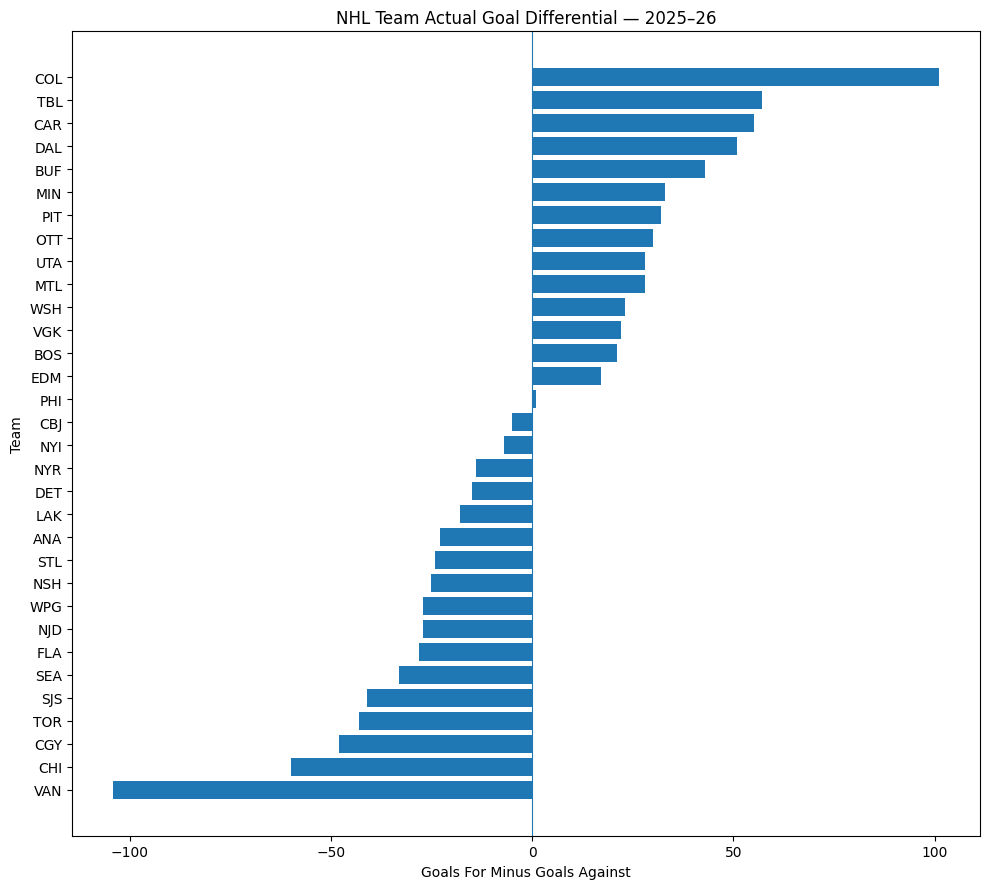

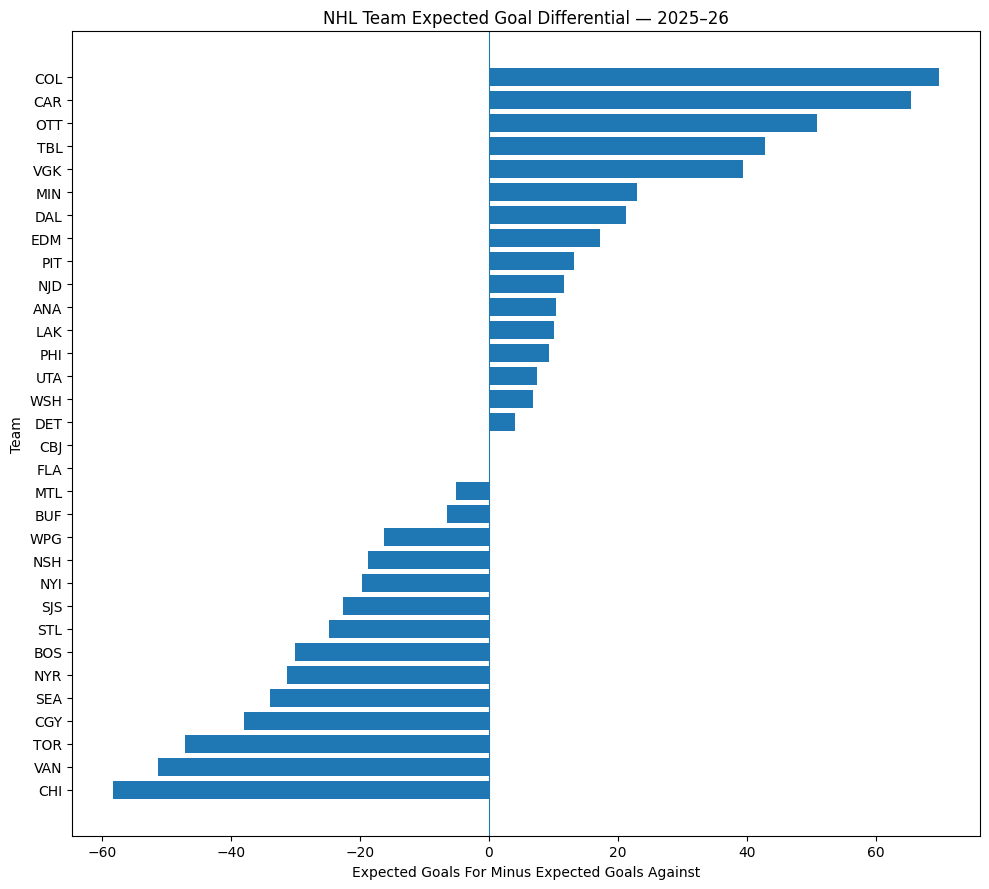

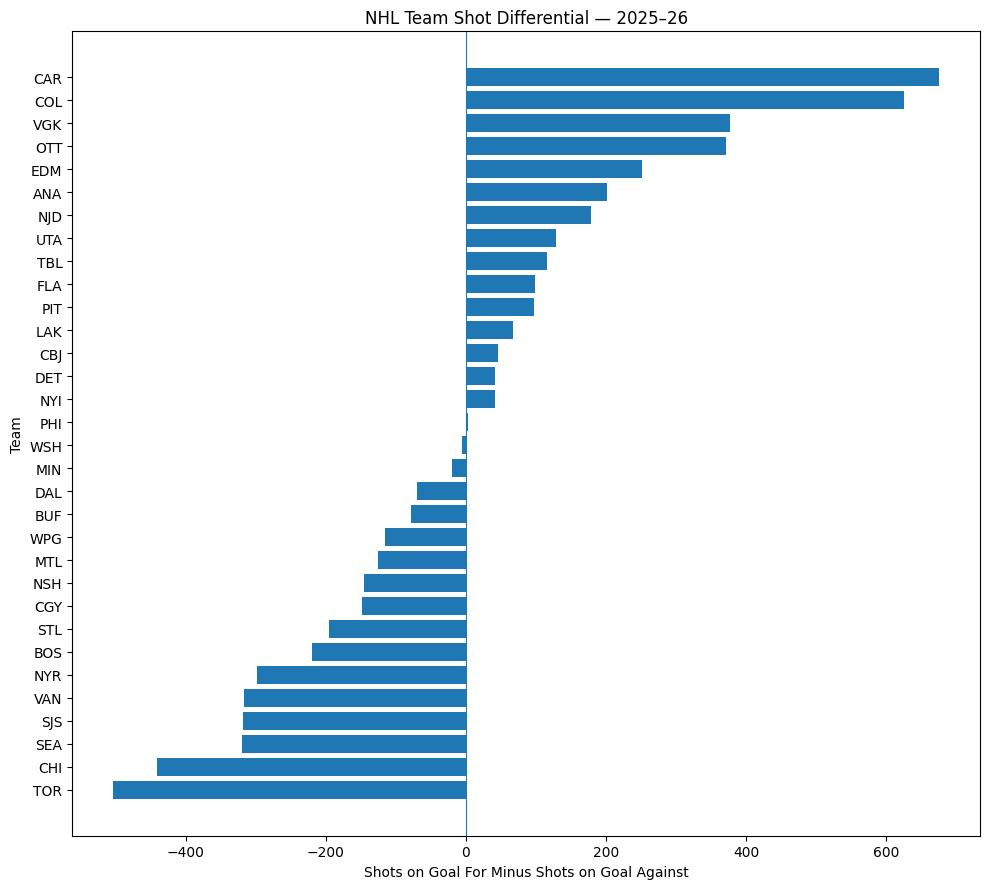

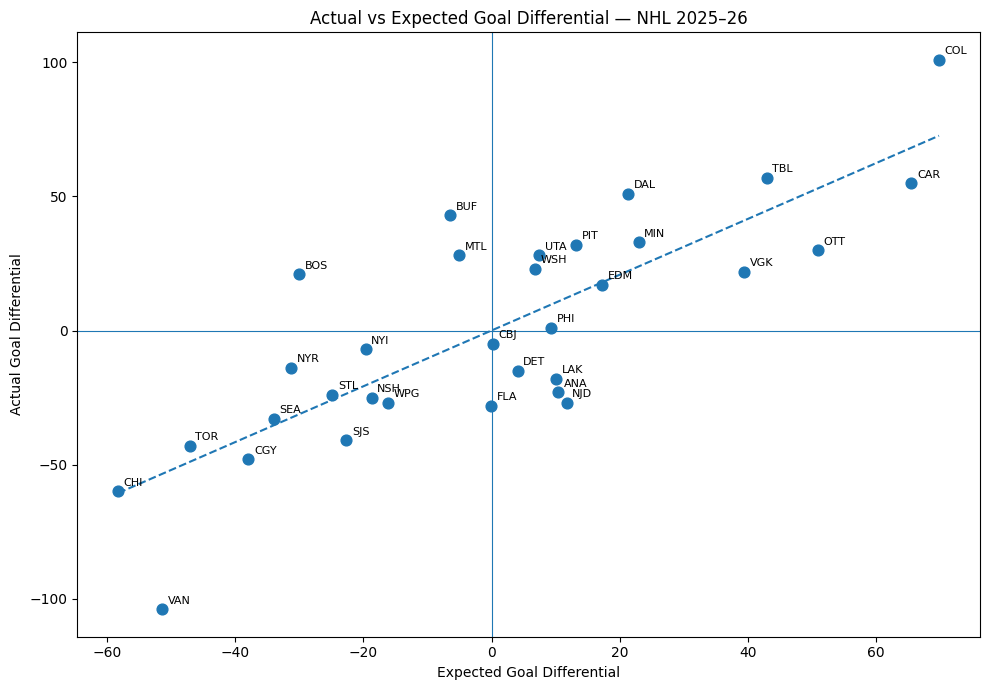

All four charts saved in the hockey_charts folder.
['03_shot_differential.png', '01_actual_goal_differential.png', '04_actual_vs_expected.png', '02_expected_goal_differential.png']


In [16]:

import matplotlib.pyplot as plt
import numpy as np
import os
from IPython.display import display, Image

# Create a folder for all project charts
os.makedirs("hockey_charts", exist_ok=True)

# Use overall statistics only
overall = df[df["situation"] == "all"].copy()

overall["actual_goal_diff"] = (
    overall["goalsfor"] - overall["goalsagainst"]
)
overall["expected_goal_diff"] = (
    overall["xgoalsfor"] - overall["xgoalsagainst"]
)
overall["shot_diff"] = (
    overall["shotsongoalfor"] - overall["shotsongoalagainst"]
)

# Chart 1: Actual goal differential
chart1 = overall.sort_values("actual_goal_diff")
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(chart1["team"], chart1["actual_goal_diff"])
ax.axvline(0, linewidth=0.8)
ax.set_title("NHL Team Actual Goal Differential — 2025–26")
ax.set_xlabel("Goals For Minus Goals Against")
ax.set_ylabel("Team")
ax.grid(False)
fig.tight_layout()
fig.savefig("hockey_charts/01_actual_goal_differential.png", dpi=300,
            bbox_inches="tight")
plt.show()
plt.close(fig)

# Chart 2: Expected goal differential
chart2 = overall.sort_values("expected_goal_diff")
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(chart2["team"], chart2["expected_goal_diff"])
ax.axvline(0, linewidth=0.8)
ax.set_title("NHL Team Expected Goal Differential — 2025–26")
ax.set_xlabel("Expected Goals For Minus Expected Goals Against")
ax.set_ylabel("Team")
ax.grid(False)
fig.tight_layout()
fig.savefig("hockey_charts/02_expected_goal_differential.png", dpi=300,
            bbox_inches="tight")
plt.show()
plt.close(fig)

# Chart 3: Shot differential
chart3 = overall.sort_values("shot_diff")
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(chart3["team"], chart3["shot_diff"])
ax.axvline(0, linewidth=0.8)
ax.set_title("NHL Team Shot Differential — 2025–26")
ax.set_xlabel("Shots on Goal For Minus Shots on Goal Against")
ax.set_ylabel("Team")
ax.grid(False)
fig.tight_layout()
fig.savefig("hockey_charts/03_shot_differential.png", dpi=300,
            bbox_inches="tight")
plt.show()
plt.close(fig)

# Chart 4: Actual vs expected goal differential
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(overall["expected_goal_diff"],
           overall["actual_goal_diff"], s=60)

for _, row in overall.iterrows():
    ax.annotate(
        row["team"],
        (row["expected_goal_diff"], row["actual_goal_diff"]),
        xytext=(4, 4), textcoords="offset points", fontsize=8
    )

slope, intercept = np.polyfit(
    overall["expected_goal_diff"], overall["actual_goal_diff"], 1
)
x_line = np.linspace(
    overall["expected_goal_diff"].min(),
    overall["expected_goal_diff"].max(), 100
)
ax.plot(x_line, slope * x_line + intercept, linestyle="--")
ax.axhline(0, linewidth=0.8)
ax.axvline(0, linewidth=0.8)
ax.set_title("Actual vs Expected Goal Differential — NHL 2025–26")
ax.set_xlabel("Expected Goal Differential")
ax.set_ylabel("Actual Goal Differential")
ax.grid(False)
fig.tight_layout()
fig.savefig("hockey_charts/04_actual_vs_expected.png", dpi=300,
            bbox_inches="tight")
plt.show()
plt.close(fig)

print("All four charts saved in the hockey_charts folder.")
print(os.listdir("hockey_charts"))


In [10]:

print("Dataset shape:", df.shape)

print("\nSeasons:")
print(df["season"].value_counts(dropna=False))

print("\nUnique teams:", df["team"].nunique())
print(sorted(df["team"].dropna().unique()))

print("\nSituations:")
print(df["situation"].value_counts(dropna=False))

print("\nAll column names:")
for col in df.columns:
    print(col)


Dataset shape: (160, 107)

Seasons:
season
2025    160
Name: count, dtype: int64

Unique teams: 32
['ANA', 'BOS', 'BUF', 'CAR', 'CBJ', 'CGY', 'CHI', 'COL', 'DAL', 'DET', 'EDM', 'FLA', 'LAK', 'MIN', 'MTL', 'NJD', 'NSH', 'NYI', 'NYR', 'OTT', 'PHI', 'PIT', 'SEA', 'SJS', 'STL', 'TBL', 'TOR', 'UTA', 'VAN', 'VGK', 'WPG', 'WSH']

Situations:
situation
other    32
all      32
5on5     32
4on5     32
5on4     32
Name: count, dtype: int64

All column names:
team
season
name
team.1
position
situation
games_played
xgoalspercentage
corsipercentage
fenwickpercentage
icetime
xongoalfor
xgoalsfor
xreboundsfor
xfreezefor
xplaystoppedfor
xplaycontinuedinzonefor
xplaycontinuedoutsidezonefor
flurryadjustedxgoalsfor
scorevenueadjustedxgoalsfor
flurryscorevenueadjustedxgoalsfor
shotsongoalfor
missedshotsfor
blockedshotattemptsfor
shotattemptsfor
goalsfor
reboundsfor
reboundgoalsfor
freezefor
playstoppedfor
playcontinuedinzonefor
playcontinuedoutsidezonefor
savedshotsongoalfor
savedunblockedshotattemptsfor
p

In [11]:

# Identify columns relevant to NHL team performance

print("TEAM PERFORMANCE VARIABLES")
print("-" * 40)

keywords = [
    "team", "season", "situation", "games",
    "goalsfor", "goalsagainst",
    "xgoalsfor", "xgoalsagainst",
    "shotsongoalfor", "shotsongoalagainst",
    "shotattemptsfor", "shotattemptsagainst",
    "corsi", "fenwick", "points"
]

for col in df.columns:
    if any(word in col.lower().replace("_", "") for word in keywords):
        print(col)

print("\nROWS BY SITUATION")
print(df["situation"].value_counts(dropna=False))

print("\nNUMBER OF UNIQUE TEAMS")
print(df["team"].nunique())



TEAM PERFORMANCE VARIABLES
----------------------------------------
team
season
team.1
situation
games_played
corsipercentage
fenwickpercentage
xgoalsfor
flurryadjustedxgoalsfor
scorevenueadjustedxgoalsfor
flurryscorevenueadjustedxgoalsfor
shotsongoalfor
blockedshotattemptsfor
shotattemptsfor
goalsfor
reboundgoalsfor
savedshotsongoalfor
savedunblockedshotattemptsfor
lowdangerxgoalsfor
mediumdangerxgoalsfor
highdangerxgoalsfor
lowdangergoalsfor
mediumdangergoalsfor
highdangergoalsfor
unblockedshotattemptsfor
scoreadjustedunblockedshotattemptsfor
reboundxgoalsfor
xgoalsagainst
flurryadjustedxgoalsagainst
scorevenueadjustedxgoalsagainst
flurryscorevenueadjustedxgoalsagainst
shotsongoalagainst
blockedshotattemptsagainst
shotattemptsagainst
goalsagainst
reboundgoalsagainst
savedshotsongoalagainst
savedunblockedshotattemptsagainst
lowdangerxgoalsagainst
mediumdangerxgoalsagainst
highdangerxgoalsagainst
lowdangergoalsagainst
mediumdangergoalsagainst
highdangergoalsagainst
unblockedshotattempt

Expected goals for: xgoalsfor
Expected goals against: xgoalsagainst
Goals for: goalsfor
Goals against: goalsagainst


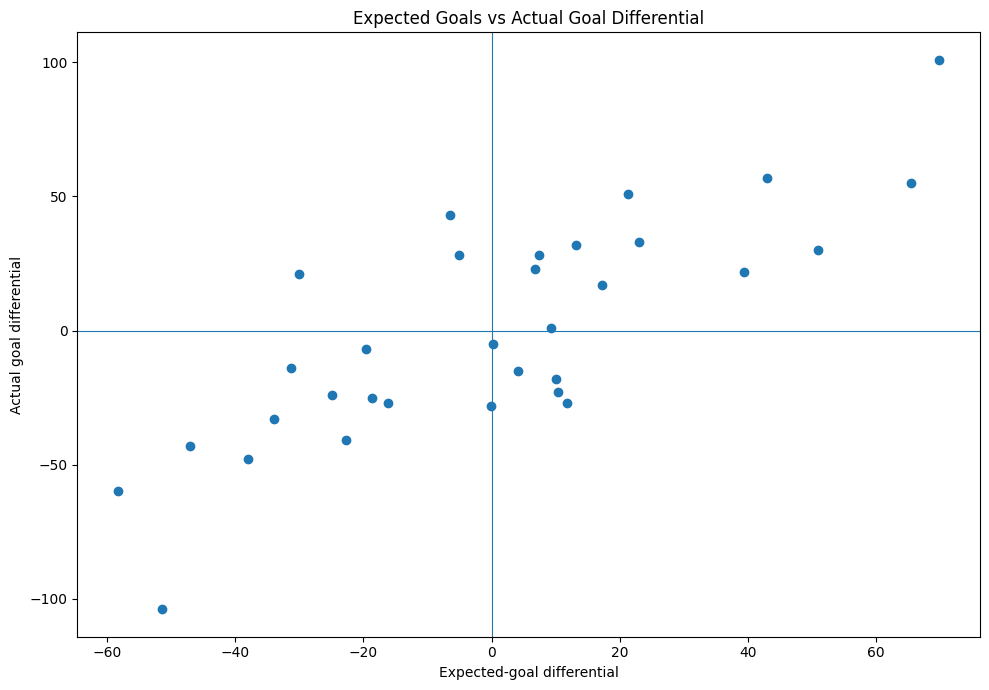

Teams included: 32


,team,expected_goal_diff,actual_goal_diff
71,COL,69.79,101.0
131,CAR,65.49,55.0
31,OTT,50.87,30.0
46,TBL,42.92,57.0
66,VGK,39.40,22.0
136,MIN,22.96,33.0
116,DAL,21.33,51.0
41,EDM,17.31,17.0
91,PIT,13.22,32.0
21,NJD,11.73,-27.0


In [12]:

# Select overall team rows
overall = df[
    df["situation"].astype(str).str.strip().str.lower() == "all"
].copy()

# Find columns using their names
def find_col(candidates):
    for candidate in candidates:
        if candidate in overall.columns:
            return candidate
    return None

xgf = find_col(["xgoalsfor", "x_goals_for"])
xga = find_col(["xgoalsagainst", "x_goals_against"])
gf = find_col(["goalsfor", "goals_for"])
ga = find_col(["goalsagainst", "goals_against"])

print("Expected goals for:", xgf)
print("Expected goals against:", xga)
print("Goals for:", gf)
print("Goals against:", ga)

if all([xgf, xga, gf, ga]):
    for col in [xgf, xga, gf, ga]:
        overall[col] = pd.to_numeric(
            overall[col], errors="coerce"
        )

    overall = overall.dropna(subset=[xgf, xga, gf, ga])
    overall = overall.drop_duplicates(subset=["team"])

    overall["expected_goal_diff"] = overall[xgf] - overall[xga]
    overall["actual_goal_diff"] = overall[gf] - overall[ga]

    import matplotlib.pyplot as plt

    plt.figure(figsize=(10, 7))
    plt.scatter(
        overall["expected_goal_diff"],
        overall["actual_goal_diff"]
    )
    plt.axhline(0, linewidth=0.8)
    plt.axvline(0, linewidth=0.8)
    plt.title("Expected Goals vs Actual Goal Differential")
    plt.xlabel("Expected-goal differential")
    plt.ylabel("Actual goal differential")
    plt.grid(False)
    plt.tight_layout()
    plt.show()

    print("Teams included:", len(overall))
    display(
        overall[
            ["team", "expected_goal_diff", "actual_goal_diff"]
        ].sort_values("expected_goal_diff", ascending=False)
    )
else:
    print(
        "\nThe required columns were not identified. "
        "Use the column names printed in Step 1 to adjust the candidates."
    )


Checking required columns...
Team: team
Situation: situation
Goals for: goalsfor
Goals against: goalsagainst
Expected goals for: xgoalsfor
Expected goals against: xgoalsagainst
Shots on goal for: shotsongoalfor
Shots on goal against: shotsongoalagainst

Team count in selected rows: 32

Team comparison table:


,team,goal_differential,expected_goal_differential,shot_differential
71,COL,101.0,69.79,625.0
46,TBL,57.0,42.92,116.0
131,CAR,55.0,65.49,675.0
116,DAL,51.0,21.33,-69.0
61,BUF,43.0,-6.46,-78.0
136,MIN,33.0,22.96,-20.0
91,PIT,32.0,13.22,98.0
31,OTT,30.0,50.87,371.0
51,UTA,28.0,7.48,128.0
16,MTL,28.0,-5.08,-125.0


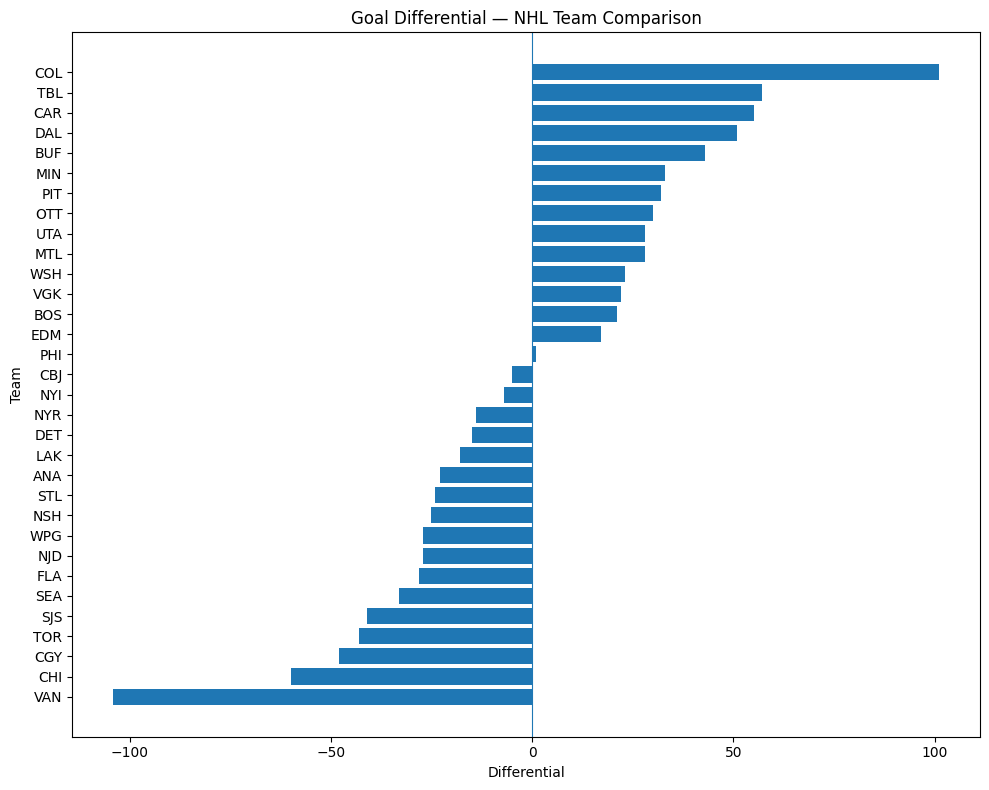

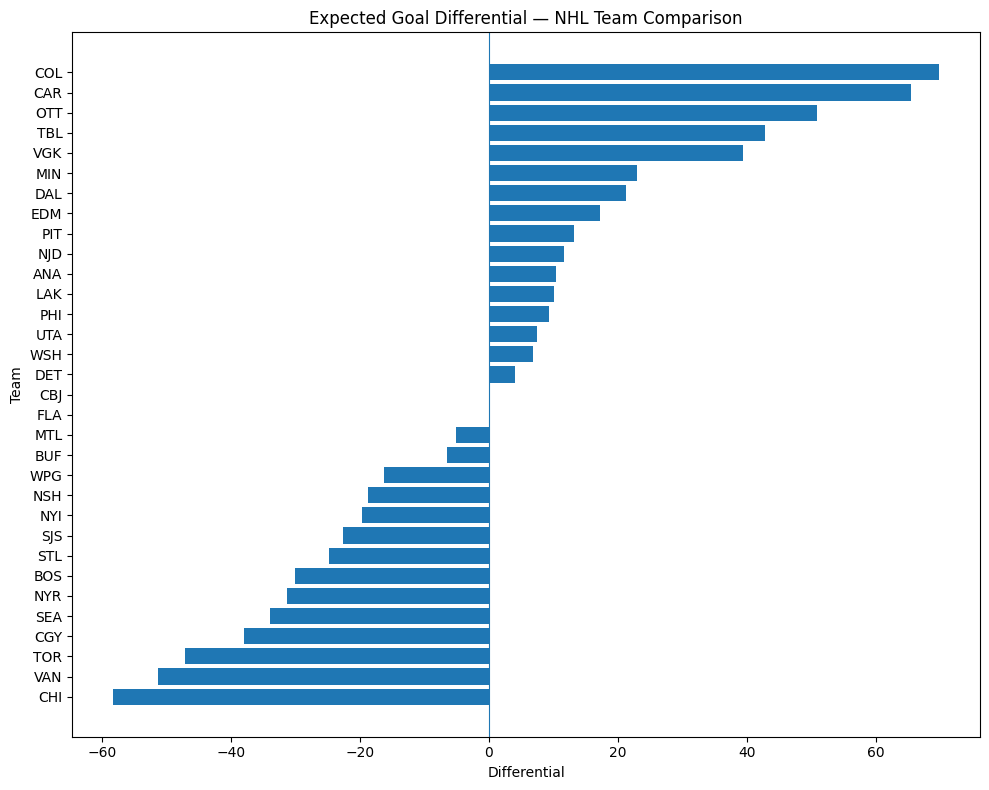

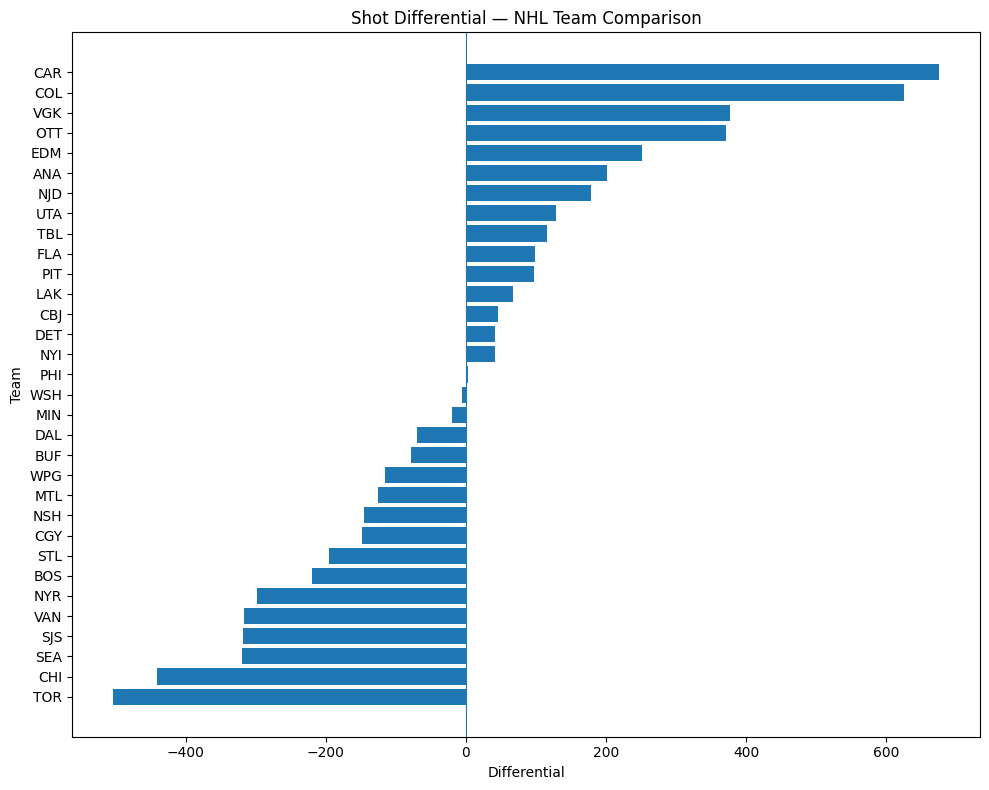


Saved: nhl_team_performance_summary.csv


In [13]:

import pandas as pd
import matplotlib.pyplot as plt
import re

# Standardize column names for matching
def normalize(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())

column_lookup = {normalize(c): c for c in df.columns}

def find_column(candidates):
    for candidate in candidates:
        if candidate in column_lookup:
            return column_lookup[candidate]
    return None

print("Checking required columns...")

team_col = find_column(["team"])
situation_col = find_column(["situation"])
gf_col = find_column(["goalsfor"])
ga_col = find_column(["goalsagainst"])
xgf_col = find_column(["xgoalsfor"])
xga_col = find_column(["xgoalsagainst"])
sf_col = find_column(["shotsongoalfor"])
sa_col = find_column(["shotsongoalagainst"])

for label, col in [
    ("Team", team_col),
    ("Situation", situation_col),
    ("Goals for", gf_col),
    ("Goals against", ga_col),
    ("Expected goals for", xgf_col),
    ("Expected goals against", xga_col),
    ("Shots on goal for", sf_col),
    ("Shots on goal against", sa_col)
]:
    print(label + ":", col if col else "Not available")

if not team_col or not situation_col:
    raise ValueError("Team or situation column is missing.")

# Select overall statistics, not special-teams rows
overall = df[
    df[situation_col].astype(str).str.strip().str.lower() == "all"
].copy()

if overall.empty:
    raise ValueError("No 'all' situation rows found.")

# One row per team for the summary
overall = overall.drop_duplicates(subset=[team_col]).copy()

# Calculate available metrics
metric_pairs = [
    ("goal_differential", gf_col, ga_col),
    ("expected_goal_differential", xgf_col, xga_col),
    ("shot_differential", sf_col, sa_col)
]

for new_col, for_col, against_col in metric_pairs:
    if for_col and against_col:
        overall[for_col] = pd.to_numeric(overall[for_col], errors="coerce")
        overall[against_col] = pd.to_numeric(overall[against_col], errors="coerce")
        overall[new_col] = overall[for_col] - overall[against_col]

available_metrics = [
    col for col, _, _ in metric_pairs if col in overall.columns
]

if not available_metrics:
    raise ValueError("No complete metric pairs were found.")

# Display summary
summary_cols = [team_col] + available_metrics
summary = overall[summary_cols].copy()

print("\nTeam count in selected rows:", len(summary))
print("\nTeam comparison table:")
display(summary.sort_values(available_metrics[0], ascending=False).round(2))

# Create a separate horizontal bar chart for each available metric
for metric in available_metrics:
    chart = summary[[team_col, metric]].dropna().sort_values(metric)

    plt.figure(figsize=(10, max(6, len(chart) * 0.25)))
    plt.barh(chart[team_col].astype(str), chart[metric])
    plt.axvline(0, linewidth=0.8)
    plt.title(metric.replace("_", " ").title() + " — NHL Team Comparison")
    plt.xlabel("Differential")
    plt.ylabel("Team")
    plt.grid(False)
    plt.tight_layout()
    plt.show()

# Save results
summary.to_csv("/content/nhl_team_performance_summary.csv", index=False)

print("\nSaved: nhl_team_performance_summary.csv")


In [14]:

import pandas as pd
import numpy as np
import re

# Work on a copy so the original data stays unchanged
check = df.copy()

def norm(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())

print("=" * 55)
print("1. DATASET OVERVIEW")
print("=" * 55)
print("Rows:", len(check))
print("Columns:", len(check.columns))

# Identify important columns without assuming exact formatting
normalized = {}
for col in check.columns:
    normalized.setdefault(norm(col), []).append(col)

def find_col(*names):
    for name in names:
        matches = normalized.get(norm(name), [])
        if matches:
            return matches[0]
    return None

team = find_col("team")
season = find_col("season")
situation = find_col("situation")
games = find_col("games_played", "gamesplayed")
gf = find_col("goalsFor", "goals_for")
ga = find_col("goalsAgainst", "goals_against")
xgf = find_col("xGoalsFor", "x_goals_for")
xga = find_col("xGoalsAgainst", "x_goals_against")
sf = find_col("shotsOnGoalFor", "shots_on_goal_for")
sa = find_col("shotsOnGoalAgainst", "shots_on_goal_against")

print("\n2. COLUMN VERIFICATION")
for label, col in [
    ("Team", team), ("Season", season), ("Situation", situation),
    ("Games played", games), ("Goals for", gf),
    ("Goals against", ga), ("Expected goals for", xgf),
    ("Expected goals against", xga),
    ("Shots on goal for", sf), ("Shots on goal against", sa)
]:
    print(f"{label}: {col}")

if team is None or situation is None:
    raise ValueError("Team or situation column not found.")

print("\n3. SEASON VALUES")
if season:
    print(check[season].value_counts(dropna=False).to_string())
else:
    print("Season column not found.")

print("\n4. SITUATION COUNTS")
print(check[situation].value_counts(dropna=False).to_string())

print("\n5. TEAM COVERAGE")
print("Unique teams overall:", check[team].nunique())
print("Team names:", sorted(check[team].dropna().astype(str).unique()))

print("\n6. MISSING VALUES")
missing = check.isna().sum()
print("Columns with missing values:", int((missing > 0).sum()))
print(missing[missing > 0].sort_values(ascending=False).head(15).to_string())

print("\n7. DUPLICATE CHECK")
print("Completely duplicate rows:", int(check.duplicated().sum()))

if season and situation:
    overall = check[
        check[situation].astype(str).str.strip().str.lower() == "all"
    ].copy()

    print("\n8. OVERALL ('all') ROW CHECK")
    print("Rows labelled all:", len(overall))
    print("Unique teams in all rows:", overall[team].nunique())
    print("Repeated team rows in all situation:",
          int(overall.duplicated(subset=[team]).sum()))

    # Calculate metrics only when all required columns exist
    required = [gf, ga, xgf, xga]
    if all(required):
        for col in required:
            overall[col] = pd.to_numeric(overall[col], errors="coerce")

        overall["actual_goal_diff"] = overall[gf] - overall[ga]
        overall["expected_goal_diff"] = overall[xgf] - overall[xga]

        valid = overall.dropna(
            subset=["actual_goal_diff", "expected_goal_diff"]
        ).drop_duplicates(subset=[team]).copy()

        print("\n9. DIFFERENTIAL CALCULATION CHECK")
        print("Teams with complete values:", len(valid))
        display(valid[
            [team, gf, ga, xgf, xga,
             "actual_goal_diff", "expected_goal_diff"]
        ].sort_values("actual_goal_diff", ascending=False).round(2))

        print("\n10. COMPARISON BETWEEN ACTUAL AND EXPECTED")
        if len(valid) >= 3:
            corr = valid["actual_goal_diff"].corr(
                valid["expected_goal_diff"]
            )
            print("Pearson correlation:", round(corr, 3))
            print("Interpretation: this measures linear association, "
                  "not causation.")
        else:
            print("Not enough complete teams to assess the relationship.")

    else:
        print("\nCannot verify goal differentials automatically.")
        print("At least one required goals or expected-goals column "
              "was not identified. Check the column names printed above.")


1. DATASET OVERVIEW
Rows: 160
Columns: 107

2. COLUMN VERIFICATION
Team: team
Season: season
Situation: situation
Games played: games_played
Goals for: goalsfor
Goals against: goalsagainst
Expected goals for: xgoalsfor
Expected goals against: xgoalsagainst
Shots on goal for: shotsongoalfor
Shots on goal against: shotsongoalagainst

3. SEASON VALUES
season
2025    160

4. SITUATION COUNTS
situation
other    32
all      32
5on5     32
4on5     32
5on4     32

5. TEAM COVERAGE
Unique teams overall: 32
Team names: ['ANA', 'BOS', 'BUF', 'CAR', 'CBJ', 'CGY', 'CHI', 'COL', 'DAL', 'DET', 'EDM', 'FLA', 'LAK', 'MIN', 'MTL', 'NJD', 'NSH', 'NYI', 'NYR', 'OTT', 'PHI', 'PIT', 'SEA', 'SJS', 'STL', 'TBL', 'TOR', 'UTA', 'VAN', 'VGK', 'WPG', 'WSH']

6. MISSING VALUES
Columns with missing values: 0
Series([], )

7. DUPLICATE CHECK
Completely duplicate rows: 0

8. OVERALL ('all') ROW CHECK
Rows labelled all: 32
Unique teams in all rows: 32
Repeated team rows in all situation: 0

9. DIFFERENTIAL CALCULATIO

,team,goalsfor,goalsagainst,xgoalsfor,xgoalsagainst,actual_goal_diff,expected_goal_diff
71,COL,298.0,197.0,301.10,231.31,101.0,69.79
46,TBL,286.0,229.0,284.40,241.48,57.0,42.92
131,CAR,291.0,236.0,300.64,235.15,55.0,65.49
116,DAL,273.0,222.0,259.26,237.93,51.0,21.33
61,BUF,283.0,240.0,258.05,264.51,43.0,-6.46
136,MIN,268.0,235.0,265.88,242.92,33.0,22.96
91,PIT,290.0,258.0,272.39,259.17,32.0,13.22
31,OTT,275.0,245.0,271.89,221.02,30.0,50.87
51,UTA,268.0,240.0,261.53,254.05,28.0,7.48
16,MTL,279.0,251.0,268.31,273.39,28.0,-5.08



10. COMPARISON BETWEEN ACTUAL AND EXPECTED
Pearson correlation: 0.807
Interpretation: this measures linear association, not causation.


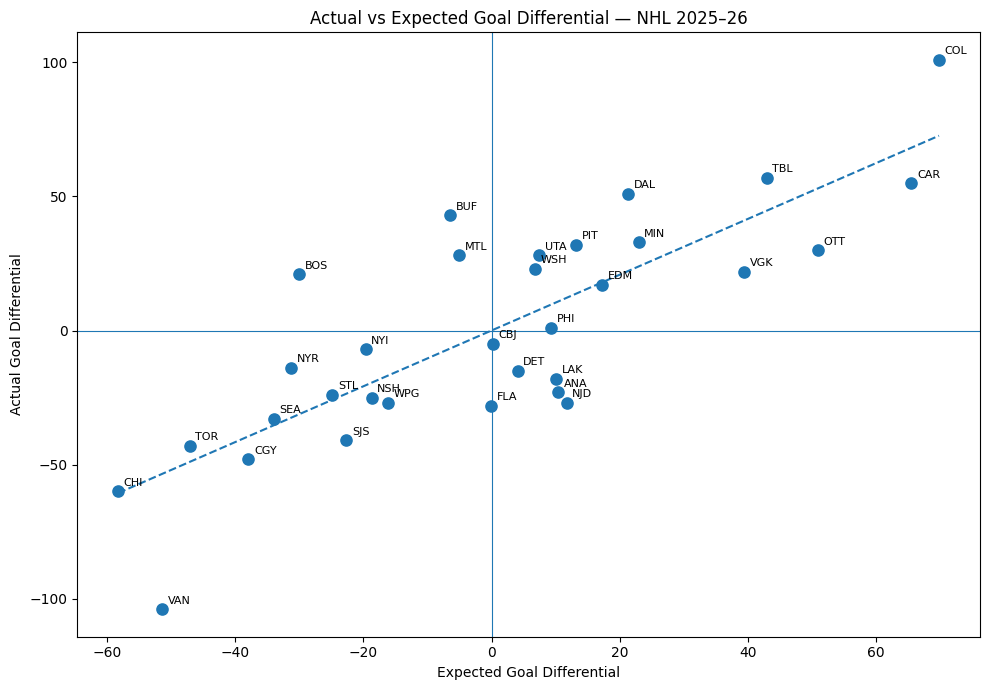

Largest positive differences:


,team,actual_goal_diff,expected_goal_diff,difference
36,BOS,21.0,-30.00,51.00
61,BUF,43.0,-6.46,49.46
16,MTL,28.0,-5.08,33.08
71,COL,101.0,69.79,31.21
116,DAL,51.0,21.33,29.67


Largest negative differences:


,team,actual_goal_diff,expected_goal_diff,difference
86,VAN,-104.0,-51.35,-52.65
21,NJD,-27.0,11.73,-38.73
151,ANA,-23.0,10.40,-33.40
6,LAK,-18.0,10.09,-28.09
96,FLA,-28.0,-0.01,-27.99


In [15]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Select one overall-statistics row per team
overall = df[df["situation"] == "all"].copy()

# Calculate differentials
overall["actual_goal_diff"] = (
    overall["goalsfor"] - overall["goalsagainst"]
)

overall["expected_goal_diff"] = (
    overall["xgoalsfor"] - overall["xgoalsagainst"]
)

# Difference between actual and expected differential
overall["difference"] = (
    overall["actual_goal_diff"] - overall["expected_goal_diff"]
)

# Scatter plot
x = overall["expected_goal_diff"]
y = overall["actual_goal_diff"]

plt.figure(figsize=(10, 7))
plt.scatter(x, y, s=65)

# Add a trend line
slope, intercept = np.polyfit(x, y, 1)
line_x = np.linspace(x.min(), x.max(), 100)
plt.plot(line_x, slope * line_x + intercept, linestyle="--")

# Label teams
for _, row in overall.iterrows():
    plt.annotate(
        row["team"],
        (row["expected_goal_diff"], row["actual_goal_diff"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.xlabel("Expected Goal Differential")
plt.ylabel("Actual Goal Differential")
plt.title("Actual vs Expected Goal Differential — NHL 2025–26")
plt.grid(False)
plt.tight_layout()
plt.show()

# Show the teams with the largest positive and negative differences
print("Largest positive differences:")
display(
    overall.nlargest(5, "difference")[
        ["team", "actual_goal_diff", "expected_goal_diff", "difference"]
    ].round(2)
)

print("Largest negative differences:")
display(
    overall.nsmallest(5, "difference")[
        ["team", "actual_goal_diff", "expected_goal_diff", "difference"]
    ].round(2)
)


In [17]:

import shutil
from google.colab import files

shutil.make_archive("hockey_charts", "zip", "hockey_charts")
files.download("hockey_charts.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>